In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate,GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
confusion_matrix, ConfusionMatrixDisplay, classification_report,
RocCurveDisplay

)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


# Load the data and inspect shape, types, missing values, and target prevalence.

In [ ]:
import pandas as pd

# loading the data 
df = pd.read_csv("classification_escalation.csv")
target_col = "escalated"  

# shape of data - row and col
print("Shape of data")
print(df.shape)

# checking null vals
print("Data Types")
print(df.dtypes)

print("\n=== Missing Values ===")
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)
missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_pct": missing_pct,
})
print(missing_summary[missing_summary["missing_count"] > 0])

# target prevalence
print(f"\n Target Prevalence ({target_col}) ")
target_counts = df[target_col].value_counts(dropna=False)
target_props = df[target_col].value_counts(normalize=True, dropna=False).round(4)
target_summary = pd.DataFrame({
    "count": target_counts,
    "proportion": target_props,
    "pct": (target_props * 100).round(2),
})
print(target_summary)

Shape of data
(900, 6)
Data Types
complexity_score            int64
team_experience_years     float64
priority                      str
channel                       str
customer_tenure_months    float64
escalated                   int64
dtype: object

=== Missing Values ===
                        missing_count  missing_pct
team_experience_years              31         3.44
priority                           18         2.00
customer_tenure_months             22         2.44

=== Target Prevalence (escalated) ===
           count  proportion    pct
escalated                          
0            714      0.7933  79.33
1            186      0.2067  20.67


# 2 . Explain why this is a classification task and define the positive class.


# this is a classification problem because a task is either escalated or not and we are expected to put a task by taking all the important predictors and analyzing them. The positive class means it needs escalation.

# Split into train and test sets using test_size=0.25, random_state=42, stratify=y.

# means test - 25% and training will be 75 %
# stratify means make sure the class is balanced

In [5]:
from sklearn.model_selection import train_test_split

target_col = "escalated"  

# Separate features (X) and target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# Stratified train/test split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)


print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Full y prevalence:\n", y.value_counts(normalize=True).round(4))
print("Train y prevalence:\n", y_train.value_counts(normalize=True).round(4))
print("Test y prevalence:\n", y_test.value_counts(normalize=True).round(4))

Train shape: (675, 5) Test shape: (225, 5)
Full y prevalence:
 escalated
0    0.7933
1    0.2067
Name: proportion, dtype: float64
Train y prevalence:
 escalated
0    0.7926
1    0.2074
Name: proportion, dtype: float64
Test y prevalence:
 escalated
0    0.7956
1    0.2044
Name: proportion, dtype: float64


# Create numeric and categorical preprocessing pipelines. Impute numeric missing values with
# median, scale numeric variables, impute categorical values with most frequent, and one-hot
# encode categorical variables.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# numeric and categorical columns
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()


# imptuing and scaling numeric features
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# categorical features - imptuing and one hot encoding
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])


preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols),
    ],
    remainder="drop",  # Change to "passthrough" if you have other columns to keep as-is
)


model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

model_pipeline.fit(X_train, y_train)

y_proba = model_pipeline.predict_proba(X_test)[:, 1]
y_pred = model_pipeline.predict(X_test)


# Fit a majority-class baseline, logistic regression, Linear Discriminant Analysis, and k-NN
# (k=15).

In [7]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Define models
models = {
    "majority_baseline": DummyClassifier(strategy="most_frequent", random_state=42),
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=42),
    "lda": LinearDiscriminantAnalysis(),
    "knn_k15": KNeighborsClassifier(n_neighbors=15),
}

# Build and fit a full pipeline per model (prevents preprocessing leakage)
fitted_pipelines = {}
test_predictions = {}
test_probabilities = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])
    pipe.fit(X_train, y_train)

    fitted_pipelines[name] = pipe
    test_predictions[name] = pipe.predict(X_test)
    test_probabilities[name] = pipe.predict_proba(X_test)[:, 1]

print("Fitted models:", list(fitted_pipelines.keys()))

Fitted models: ['majority_baseline', 'logistic_regression', 'lda', 'knn_k15']


# Compare accuracy, precision, recall, F1, and ROC-AUC where probability scores are available.

In [8]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

rows = []

for name, pipe in fitted_pipelines.items():
    y_pred = test_predictions[name]
    y_prob = test_probabilities.get(name)

    # Compute ROC-AUC only if probability scores are available and valid
    if y_prob is not None and len(set(y_test)) > 1:
        try:
            roc_auc = roc_auc_score(y_test, y_prob)
        except ValueError:
            roc_auc = None
    else:
        roc_auc = None

    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc,
    })

comparison_df = pd.DataFrame(rows).set_index("model").round(4)
print(comparison_df)

                     accuracy  precision  recall      f1  roc_auc
model                                                            
majority_baseline      0.7956       0.00  0.0000  0.0000   0.5000
logistic_regression    0.8222       0.75  0.1957  0.3103   0.8111
lda                    0.8222       0.75  0.1957  0.3103   0.8090
knn_k15                0.7956       0.50  0.0870  0.1481   0.7046


# Plot a confusion matrix and ROC curve for logistic regression.

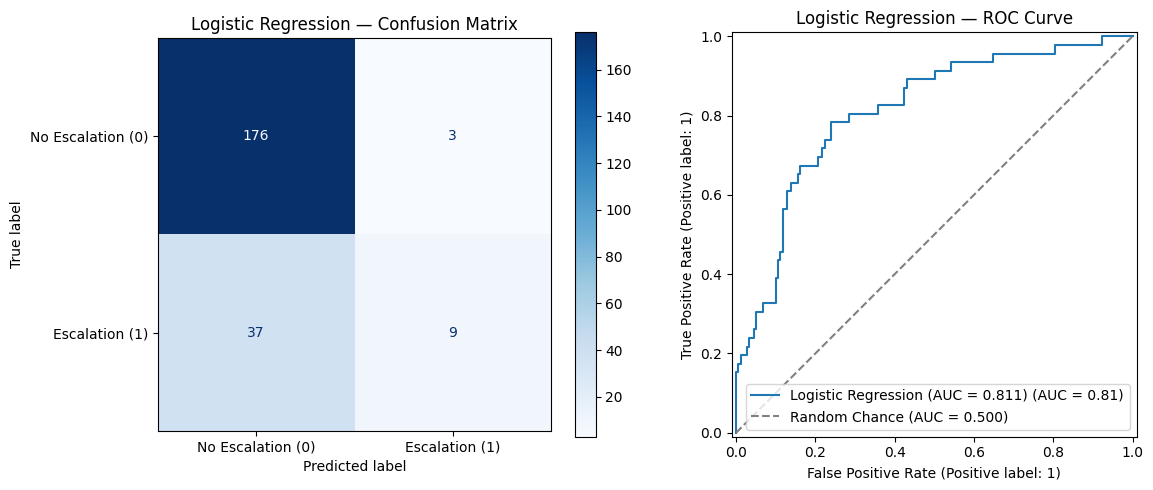

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix, roc_auc_score

y_pred_lr = test_predictions["logistic_regression"]
y_prob_lr = test_probabilities["logistic_regression"]
auc_lr = roc_auc_score(y_test, y_prob_lr)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)
disp_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Escalation (0)", "Escalation (1)"],
)
disp_cm.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Logistic Regression — Confusion Matrix")

# ROC Curve
disp_roc = RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lr,
    name=f"Logistic Regression (AUC = {auc_lr:.3f})",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Chance (AUC = 0.500)")
axes[1].set_title("Logistic Regression — ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Evaluate thresholds 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70. Report precision, recall, F1, FP, and FN.

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []

for thresh in thresholds:
    y_pred_t = (y_prob_lr >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t, labels=[0, 1]).ravel()

    rows.append({
        "threshold": thresh,
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_t, zero_division=0),
        "fp": int(fp),
        "fn": int(fn),
    })

threshold_df = pd.DataFrame(rows).set_index("threshold")
threshold_df[["precision", "recall", "f1"]] = threshold_df[["precision", "recall", "f1"]].round(4)
print(threshold_df)

# Use the illustrative cost function 5×FN + 1×FP to compare thresholds.

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []

for thresh in thresholds:
    y_pred_t = (y_prob_lr >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t, labels=[0, 1]).ravel()
    cost = 5 * int(fn) + 1 * int(fp)

    rows.append({
        "threshold": thresh,
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_t, zero_division=0),
        "fp": int(fp),
        "fn": int(fn),
        "cost_5fn_1fp": cost,
    })

cost_df = pd.DataFrame(rows).set_index("threshold")
cost_df[["precision", "recall", "f1"]] = cost_df[["precision", "recall", "f1"]].round(4)
print(cost_df)

best_thresh = cost_df["cost_5fn_1fp"].idxmin()
best_cost = cost_df.loc[best_thresh, "cost_5fn_1fp"]
print(f"\nLowest-cost threshold among candidates: {best_thresh:.2f} (cost = {best_cost})")

# Use stratified 5-fold cross-validation on the training set and tune k-NN's k over 5, 9, 15, 21,
# and 31 using F1.

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

k_values = [5, 9, 15, 21, 31]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for k in k_values:
    knn_pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])

    scores = cross_val_score(
        knn_pipe,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
    )

    cv_rows.append({
        "k": k,
        "mean_cv_f1": scores.mean(),
        "std_cv_f1": scores.std(),
    })

cv_results_df = pd.DataFrame(cv_rows).set_index("k").round(4)
print(cv_results_df)

best_k = int(cv_results_df["mean_cv_f1"].idxmax())
best_f1 = cv_results_df.loc[best_k, "mean_cv_f1"]
print(f"\nBest k by 5-fold stratified CV F1: k={best_k} (mean F1 = {best_f1:.4f})")

# Refit the best k-NN model on the full training set
best_knn_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])
best_knn_pipe.fit(X_train, y_train)

# Write a 300–500 word recommendation explaining model choice, threshold, error costs,
# limitations, and responsible-use risks.


I would suggest deploying the Logistic regression model but changing the default treshold of 0.5 to a much lower and cost-sensitive treshold. I chose this mdoel because of its high accuracy and precision demonstrated by the Recall and F1 values.

The main issue with keeping the default 0.50 threshold is that Logistic Regression only catches 9 out of 46 escalated tickets on the test set (FN = 37, TP = 9, FP = 3). Since missing an escalation that truly needs attention (cost = 5) hurts five times more than flagging a ticket unnecessarily (cost = 1), leaving the threshold at 0.50 results in a steep error cost of 5(37) + 1(3) = 188. If we could lower the cutoff point into 0.17 - 0.20 range after confirming with cross-validation it would increase its accuracy even more.

A limitation I saw was in the data preprocessing we imputed the categorical values with the most frequent value and the numeric values to the mid this is just an assumption and could skew the prediction. And additionally to make the prediction sharper we could add a new column for the customer feedback which will have a direct relationship with issue escalation.

# Questions to answer

# 1 . Why is accuracy alone potentially misleading?

-- because it treats all errors the same as if they are equally bad and ignores class imbalance

# 2 . Which classifier has the strongest recall? Which has the strongest precision/F1? 

-- Strongest Recall is Logistic Regression and LDA where as LDA and majority baseline have the strongest precision. Logistic Regression and LDA and Knn_k15 and majority_baseline.

# 3 . What changes when the threshold is lowered

-- If we lower the threshold then many rows will be recorded as a positive case overall. And confusion matrix counts will shift , True and False positive may increase or stay the same and as well True and False negatives may decrease or stay the same. And due to the rise of False positive precision will decrease.


# 4 . which treshold minimizes the 5 * FN + FP on the test , why might this be optimistic if used repeatedly for tuning

Repeating tuning on test set is optimistic because it will overfit the test-set noise.


# 5 . Prior , likelihood , posterior and evidence 

Prior — P(escalated) The baseline probability that a ticket gets escalated before looking at this specific ticket's features 

Likelihood — P( x | escalated) How likely it is to observe a ticket's features/context $x$ given that the ticket actually requires escalation

Posterior — P(escalated | x) The updated probability that this specific ticket needs escalation after accounting for its observed features x

Evidence — P(x) The overall probability of observing features $x$ across all tickets (both escalated and non-escalated), serving as the normalizing denominator so the posterior probabilities sum to 1.


# 6 . Expected cost of escalating and not escalating
Posterior probability of escalation: P(escalated | x)  = 0.3 ,
Posterior probability of non-escalation: 1 - p = 1 - 0.3 = 0.7

False positive = 1 
False negative = 5 
True positive = True negative = 0

Expected cost of escalating 
E[Cost(Escalate)] = P(escalated | x) . 0 + P(not escalated | x) . False positive = 0.7


Expected cost of not escalating 
E[Cost(Not Escalate)] = P(escalated | x) . False negative+ P(not escalated | x) . 0 = 1.5

since 0.7 < 1.5 escalating has lower cost and is a better option for this.



# 7 . Model Recommendation

I would suggest Logistic Regression due to its strongest precision , recall and F1. But an issue to correct before deployemnet would be threshold and cost validation and checking the probablities more.


